# Download, preparação e inspeção de dados (UCI - Early Stage Diabetes Risk Prediction)

<mark>Este notebook é didático e não deve ser utilizado para realizar diagnósticos</mark>

## Sobre o conjunto de dados

Este conjunto de dados reúne informações sobre sinais e sintomas de pacientes recém-diagnosticados com diabetes ou com risco de desenvolver a doença. Ele foi criado para prever o risco de diabetes em estágio inicial. Os dados foram coletados por meio de questionários aplicados diretamente aos pacientes do Hospital de Diabetes de Sylhet, em Sylhet, Bangladesh, e foram aprovados por um médico. A fonte declara que o conjunto de dados está licenciado sob a licença CC BY 4.0.

Os dados estão disponíveis no repositório da [UCI (University of California, Irvine)](https://uci.edu) e podem ser baixados diretamente do link [UCI - Early Stage Diabetes Risk Prediction](https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset).

**Artigo introdutório**<br>
[Likelihood Prediction of Diabetes at Early Stage Using Data Mining Techniques](https://www.semanticscholar.org/paper/Likelihood-Prediction-of-Diabetes-at-Early-Stage-Islam-Ferdousi/9329dec57c5f13f195220ffa7077fd0029983f07)<br>
By M. M. F. Islam, Rahatara Ferdousi, Sadikur Rahman, Humayra Yasmin Bushra. 2019<br>
Published in Computer Vision and Machine Intelligence in Medical Image Analysis

DOI: https://doi.org/10.24432/C5VG8H.

## Bibliotecas e caminhos

As pastas são criadas automaticamente. O Parquet e os arquivos de origem ficam em `data/`, ignorada pelo Git.

### Bibliotecas

In [104]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import io
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")


def find_project_root():
    """Procura o diretório raiz do projeto."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml" / "pyproject.toml").is_file() and (
            candidate / "README.md"
        ).is_file():
            return candidate
    raise FileNotFoundError("Abra o notebook dentro deste repositório.")

### Variáveis

In [105]:
PROJECT_ROOT = find_project_root()

DATASET_URL = "https://archive.ics.uci.edu/static/public/529/early%2Bstage%2Bdiabetes%2Brisk%2Bprediction%2Bdataset.zip"
SOURCE_PAGE = "https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset"
DATA_DIR = PROJECT_ROOT / "data" / "uci-diabetes"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "diabetes_data_upload.csv"
PARQUET_PATH = DATA_DIR / "diabetes.parquet"
METADATA_PATH = DATA_DIR / "source.json"

COLUMN_TRANSLATIONS = {
    "Age": "idade",
    "Gender": "genero",
    "Polyuria": "poliuria",
    "Polydipsia": "polidipsia",
    "sudden weight loss": "perda_de_peso_repentina",
    "weakness": "fraqueza",
    "Polyphagia": "polifagia",
    "Genital thrush": "candidiase_genital",
    "visual blurring": "visao_turva",
    "Itching": "coceira",
    "Irritability": "irritabilidade",
    "delayed healing": "cicatrizacao_lenta",
    "partial paresis": "paresia_parcial",
    "muscle stiffness": "rigidez_muscular",
    "Alopecia": "alopecia",
    "Obesity": "obesidade",
    "class": "classe",
}

EXPECTED_COLUMNS = [
    "Age",
    "Gender",
    "Polyuria",
    "Polydipsia",
    "sudden weight loss",
    "weakness",
    "Polyphagia",
    "Genital thrush",
    "visual blurring",
    "Itching",
    "Irritability",
    "delayed healing",
    "partial paresis",
    "muscle stiffness",
    "Alopecia",
    "Obesity",
    "class",
]

YES_NO_COLUMNS = [
    column for column in EXPECTED_COLUMNS if column not in {"Age", "Gender", "class"}
]
YES_NO_VALUES = {"Yes": 1, "No": 0}
TARGET_VALUES = {"Negative": 0, "Positive": 1}
TARGET = COLUMN_TRANSLATIONS["class"]
FORCE_DOWNLOAD = False

print(f"Pasta de dados: {DATA_DIR.relative_to(PROJECT_ROOT).as_posix()}")

Pasta de dados: data/uci-diabetes


## Download e leitura

O arquivo existente é reutilizado. Para baixar novamente, altere `FORCE_DOWNLOAD`. O conteúdo recebido é validado antes de substituir o CSV local; uma falha de rede pode ser corrigida executando a célula novamente.

In [106]:
if FORCE_DOWNLOAD or not CSV_PATH.is_file():

    response = requests.get(DATASET_URL, timeout=(15, 60))
    response.raise_for_status()

    # Lê somente o CSV esperado; não extrai caminhos arbitrários do ZIP.
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        members = [
            name for name in archive.namelist() if Path(name).name == CSV_PATH.name
        ]
        if len(members) != 1:
            raise ValueError("O ZIP não contém um único CSV com o nome esperado.")
        csv_bytes = archive.read(members[0])

    candidate = pd.read_csv(io.BytesIO(csv_bytes))

    if candidate.empty or list(candidate.columns) != EXPECTED_COLUMNS:
        raise ValueError(
            "O arquivo recebido está vazio ou seu esquema mudou. Confira a fonte."
        )

    temporary_path = CSV_PATH.with_suffix(".csv.part")
    temporary_path.write_bytes(csv_bytes)
    temporary_path.replace(CSV_PATH)

    metadata = {
        "source_page": SOURCE_PAGE,
        "download_url": DATASET_URL,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "csv_sha256": hashlib.sha256(csv_bytes).hexdigest(),
    }

    METADATA_PATH.write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    print("Download concluído.")
else:
    print("Usando o CSV já disponível.")

data = pd.read_csv(CSV_PATH)

if data.empty or list(data.columns) != EXPECTED_COLUMNS:
    raise ValueError("CSV local vazio ou com colunas inesperadas. Confira o arquivo.")

raw_target = "class"
expected_classes = set(TARGET_VALUES)

if data[raw_target].isna().any() or set(data[raw_target].unique()) != expected_classes:
    raise ValueError("A coluna alvo contém valores ausentes ou classes inesperadas.")

print("Visualização do conjunto de dados original:")
display(data.head())

Usando o CSV já disponível.
Visualização do conjunto de dados original:


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


## Preparação e salvamento em Parquet

Abaixo, o conjunto de dados original é transformado: as colunas são traduzidas para PT-BR, normalizadas em `lowercase` com `_` como separador, os atributos `Yes`/`No` são convertidos para `1`/`0` e a variável alvo `Positive`/`Negative` é convertida para `1`/`0`. A prévia permite comparar o resultado com o CSV original exibido na seção anterior. Não removemos duplicatas, imputamos ausências, codificamos outras categorias ou normalizamos atributos. Essas decisões ficam para os experimentos posteriores.

In [107]:
for column in YES_NO_COLUMNS:
    if data[column].isna().any() or set(data[column].unique()) != set(YES_NO_VALUES):
        raise ValueError(f"A coluna {column!r} contém valores ausentes ou inesperados.")

data = data.rename(columns=COLUMN_TRANSLATIONS)
yes_no_columns = [COLUMN_TRANSLATIONS[column] for column in YES_NO_COLUMNS]
data[yes_no_columns] = data[yes_no_columns].replace(YES_NO_VALUES).astype("int8")
data[TARGET] = data[TARGET].replace(TARGET_VALUES).astype("int8")

print("Visualização do conjunto de dados preparado:")
display(data.head())

temporary_parquet = PARQUET_PATH.with_suffix(".parquet.part")
data.to_parquet(temporary_parquet, engine="pyarrow", index=False)
restored = pd.read_parquet(temporary_parquet, engine="pyarrow")
pd.testing.assert_frame_equal(data, restored)
temporary_parquet.replace(PARQUET_PATH)

print(f"Parquet salvo e conferido: {PARQUET_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"{len(data):,} registros; {len(data.columns)} colunas.")

Visualização do conjunto de dados preparado:


,idade,genero,poliuria,polidipsia,perda_de_peso_repentina,fraqueza,polifagia,candidiase_genital,visao_turva,coceira,irritabilidade,cicatrizacao_lenta,paresia_parcial,rigidez_muscular,alopecia,obesidade,classe
0,40,Male,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,Male,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,Male,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,Male,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,Male,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


Parquet salvo e conferido: data/uci-diabetes/diabetes.parquet
520 registros; 17 colunas.


## Estrutura e qualidade dos dados

Observe tipos, valores ausentes e duplicatas. Registros iguais não são automaticamente erros; avalie seu significado antes de removê-los.

In [108]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   idade                    520 non-null    int64
 1   genero                   520 non-null    str  
 2   poliuria                 520 non-null    int8 
 3   polidipsia               520 non-null    int8 
 4   perda_de_peso_repentina  520 non-null    int8 
 5   fraqueza                 520 non-null    int8 
 6   polifagia                520 non-null    int8 
 7   candidiase_genital       520 non-null    int8 
 8   visao_turva              520 non-null    int8 
 9   coceira                  520 non-null    int8 
 10  irritabilidade           520 non-null    int8 
 11  cicatrizacao_lenta       520 non-null    int8 
 12  paresia_parcial          520 non-null    int8 
 13  rigidez_muscular         520 non-null    int8 
 14  alopecia                 520 non-null    int8 
 15  obesidade        

In [109]:
quality = pd.DataFrame(
    {
        "tipo": data.dtypes.astype(str),
        "ausentes": data.isna().sum(),
        "ausentes_percentual": data.isna().mean().mul(100).round(2),
        "valores_distintos": data.nunique(dropna=False),
    }
)

display(quality)

,tipo,ausentes,ausentes_percentual,valores_distintos
idade,int64,0,0.0,51
genero,str,0,0.0,2
poliuria,int8,0,0.0,2
polidipsia,int8,0,0.0,2
perda_de_peso_repentina,int8,0,0.0,2
fraqueza,int8,0,0.0,2
polifagia,int8,0,0.0,2
candidiase_genital,int8,0,0.0,2
visao_turva,int8,0,0.0,2
coceira,int8,0,0.0,2


In [110]:
print(f"Linhas inteiramente duplicadas: {data.duplicated().sum()}")

Linhas inteiramente duplicadas: 269


In [111]:
display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
idade,520.0,NaN,NaN,NaN,48.028846,12.151466,16.0,39.0,47.5,57.0,90.0
genero,520,2,Male,328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poliuria,520.0,NaN,NaN,NaN,0.496154,0.500467,0.0,0.0,0.0,1.0,1.0
polidipsia,520.0,NaN,NaN,NaN,0.448077,0.497776,0.0,0.0,0.0,1.0,1.0
perda_de_peso_repentina,520.0,NaN,NaN,NaN,0.417308,0.493589,0.0,0.0,0.0,1.0,1.0
fraqueza,520.0,NaN,NaN,NaN,0.586538,0.492928,0.0,0.0,1.0,1.0,1.0
polifagia,520.0,NaN,NaN,NaN,0.455769,0.498519,0.0,0.0,0.0,1.0,1.0
candidiase_genital,520.0,NaN,NaN,NaN,0.223077,0.41671,0.0,0.0,0.0,0.0,1.0
visao_turva,520.0,NaN,NaN,NaN,0.448077,0.497776,0.0,0.0,0.0,1.0,1.0
coceira,520.0,NaN,NaN,NaN,0.486538,0.5003,0.0,0.0,0.0,1.0,1.0


## Balanceamento das classes

As proporções são calculadas diretamente do arquivo. O balanceamento influencia a escolha de métricas e a futura separação dos dados.

In [112]:
class_labels = {0: "Negativo (0)", 1: "Positivo (1)"}

counts = data[TARGET].value_counts().sort_index()

balance = pd.DataFrame({"quantidade": counts, "percentual": counts.div(len(data)).mul(100).round(2)})
balance.index = [class_labels[int(value)] for value in balance.index]

display(balance)

,quantidade,percentual
Negativo (0),200,38.46
Positivo (1),320,61.54


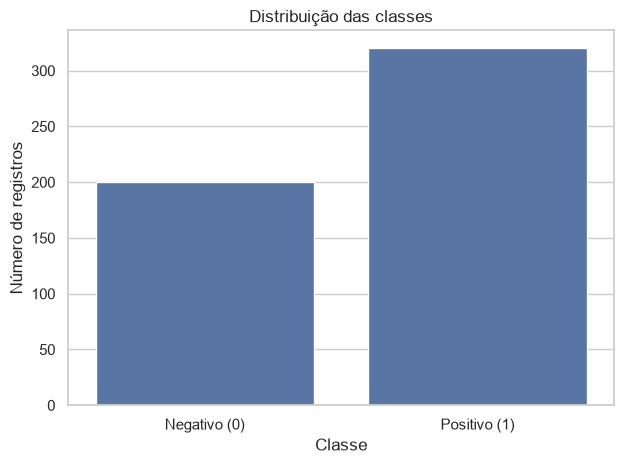

In [113]:
ax = sns.barplot(x=balance.index, y=balance["quantidade"], color="#4c72b0")
ax.set(title="Distribuição das classes", xlabel="Classe", ylabel="Número de registros")

plt.tight_layout()
plt.show()

## Distribuição das variáveis

Os gráficos são descritivos: diferenças entre grupos e correlações não demonstram causalidade.

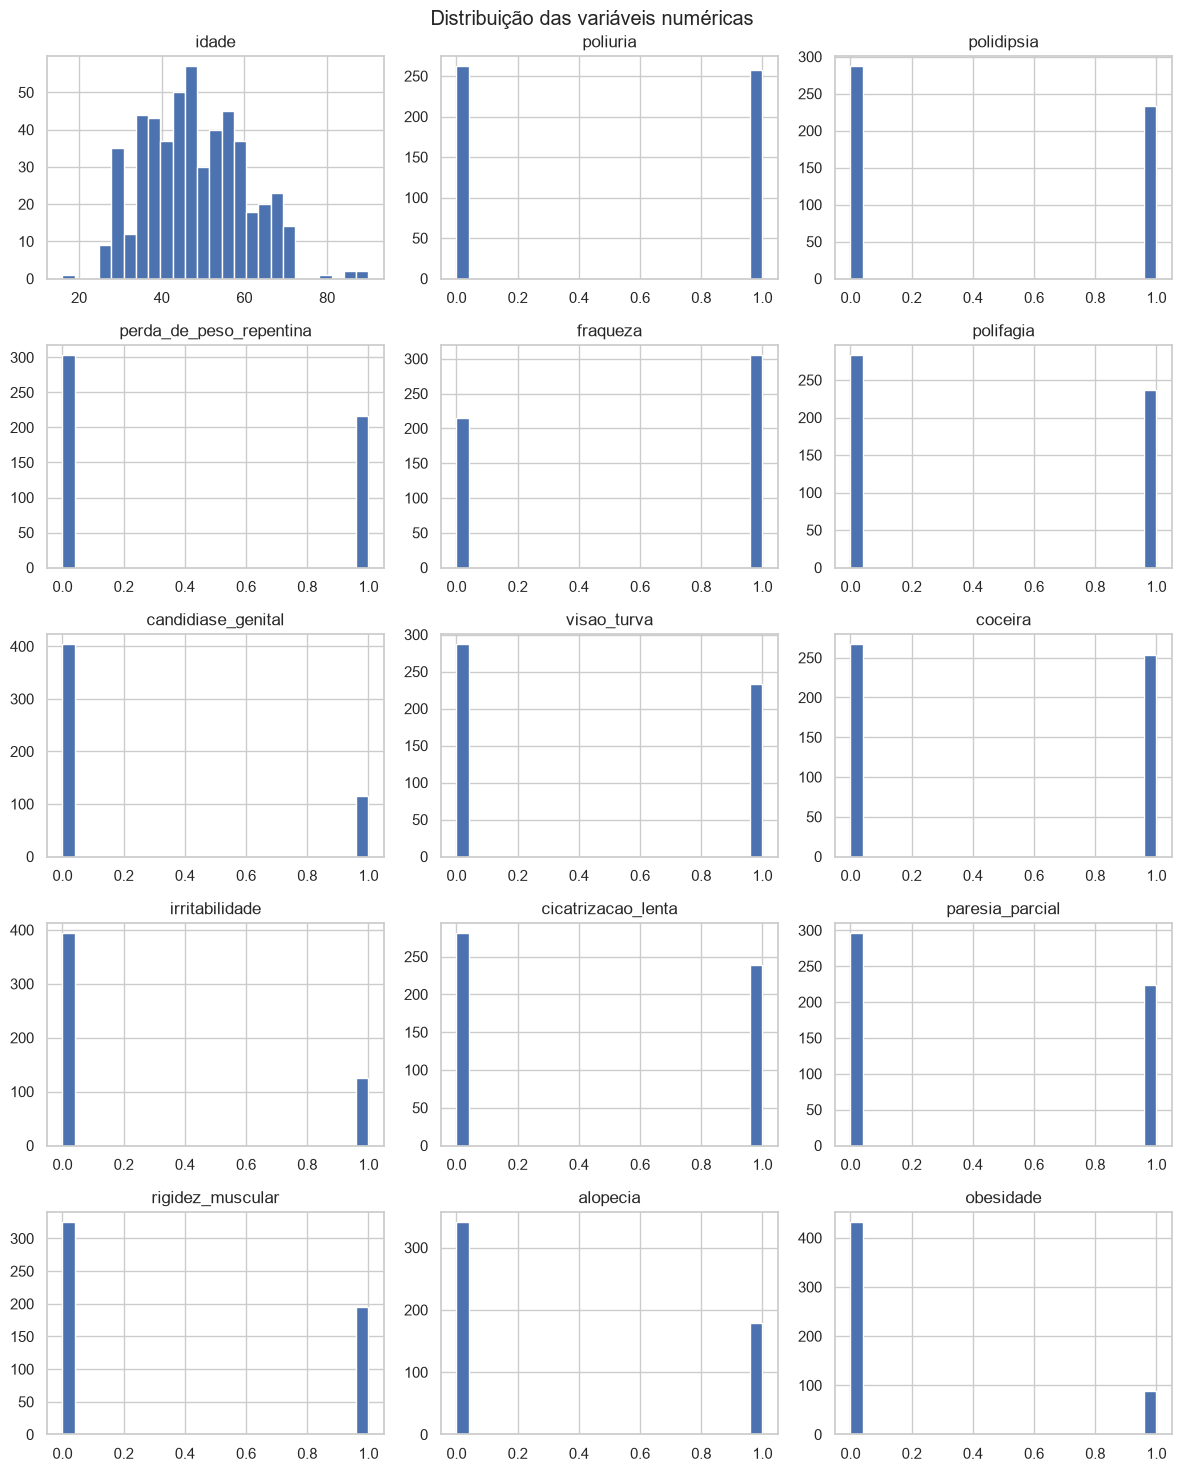

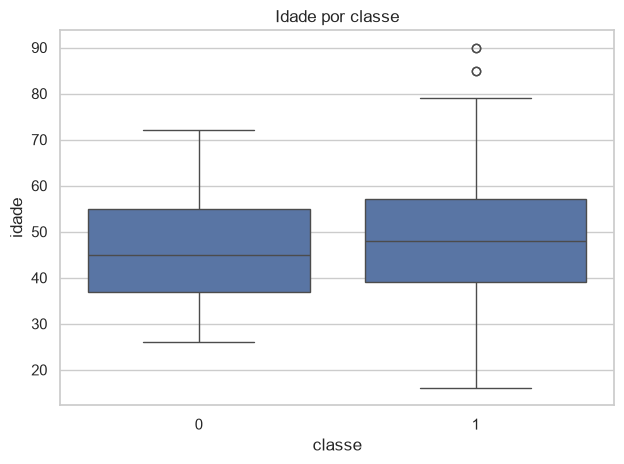

In [114]:
numeric_columns = [
    name
    for name in data.select_dtypes(include="number").columns
    if name not in {TARGET, "id_paciente"}
]

if numeric_columns:
    data[numeric_columns].hist(
        bins=25,
        figsize=(12, max(3, 3 * ((len(numeric_columns) + 2) // 3))),
        layout=((len(numeric_columns) + 2) // 3, 3),
    )
    plt.suptitle("Distribuição das variáveis numéricas")
    plt.tight_layout()
    plt.show()

if "idade" in data:
    sns.boxplot(data=data, x=TARGET, y="idade")
    plt.title("Idade por classe")
    plt.tight_layout()
    plt.show()

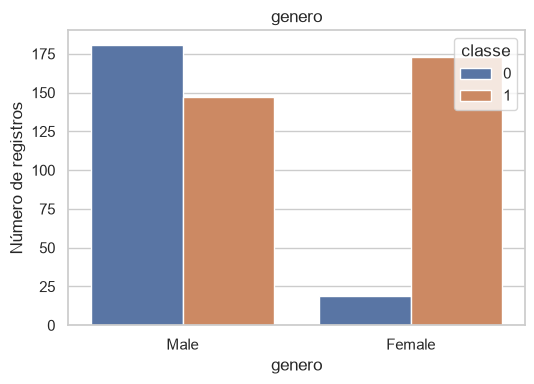

In [115]:
categorical_columns = [
    name for name in data.select_dtypes(exclude="number").columns if name != TARGET
]

fig, axes = plt.subplots(
    (len(categorical_columns) + 2) // 3,
    3,
    figsize=(15, 4 * ((len(categorical_columns) + 2) // 3)),
    squeeze=False,
)

for ax, column in zip(axes.flat, categorical_columns):
    sns.countplot(data=data, x=column, hue=TARGET, ax=ax)
    ax.set_title(column)
    ax.set_ylabel("Número de registros")

for ax in list(axes.flat)[len(categorical_columns) :]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()